<a href="https://colab.research.google.com/github/Sravya63/aiandml/blob/main/Assignment_October_12_Linear_Regression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression

# Load the correct dataset selected by the user
file_path = '/salary_regression_train.csv'
df = pd.read_csv(file_path)

# Display the first few rows and column names to understand the structure
print("Columns in dataset:", df.columns.tolist())
display(df.head())

Columns in dataset: ['YearsExperience', 'Salary']


,YearsExperience,Salary
0,1.1,39343.0
1,1.3,46205.0
2,1.5,37731.0
3,2.0,43525.0
4,2.2,39891.0


Using 'YearsExperience' as independent variable and 'Salary' as dependent variable.

Predicted Salary for 7 years of experience: 91941.94


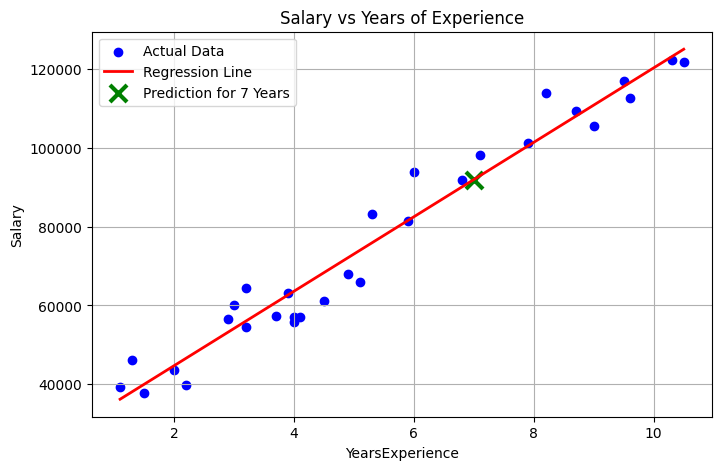

In [3]:
# Assuming the dataset has columns related to Experience and Salary.
# If the column names differ, please adjust them accordingly.
# We will find the most likely columns for experience and salary.

exp_col = [col for col in df.columns if 'exper' in col.lower()]
sal_col = [col for col in df.columns if 'sal' in col.lower()]

if exp_col and sal_col:
    X = df[[exp_col[0]]].values
    y = df[sal_col[0]].values

    # Initialize and fit the Linear Regression model
    model = LinearRegression()
    model.fit(X, y)

    # Predict salary for 7 years of experience
    years_exp = np.array([[7]])
    predicted_salary = model.predict(years_exp)[0]

    print(f"Using '{exp_col[0]}' as independent variable and '{sal_col[0]}' as dependent variable.")
    print(f"\nPredicted Salary for 7 years of experience: {predicted_salary:.2f}")

    # Plot the regression line
    plt.figure(figsize=(8, 5))
    plt.scatter(X, y, color='blue', label='Actual Data')
    plt.plot(X, model.predict(X), color='red', linewidth=2, label='Regression Line')
    plt.scatter(7, predicted_salary, color='green', marker='x', s=150, linewidth=3, label='Prediction for 7 Years')
    plt.xlabel(exp_col[0])
    plt.ylabel(sal_col[0])
    plt.title('Salary vs Years of Experience')
    plt.legend()
    plt.grid(True)
    plt.show()
else:
    print("Could not automatically detect 'Experience' and 'Salary' columns. Please check the dataset columns printed above.")

In [4]:
# Calculate and print the R-squared value for the linear regression model
if 'exp_col' in globals() and 'sal_col' in globals() and 'model' in globals():
    r_squared = model.score(X, y)
    print(f"R-squared (coefficient of determination) value: {r_squared:.4f}")
else:
    print("Error: 'exp_col', 'sal_col', or 'model' not defined in active memory. Please run cell 72f3073d first to train the model.")

R-squared (coefficient of determination) value: 0.9570


In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

if 'exp_col' in globals() and 'sal_col' in globals() and 'model' in globals():
    # Calculate predictions and residuals
    y_pred = model.predict(X)
    residuals = y - y_pred

    # Calculate metrics
    mae = mean_absolute_error(y, y_pred)
    mse = mean_squared_error(y, y_pred)
    rmse = np.sqrt(mse)

    print("--- Model Evaluation Metrics ---")
    print(f"Mean Absolute Error (MAE): {mae:.2f}")
    print(f"Mean Squared Error (MSE): {mse:.2f}")
    print(f"Root Mean Squared Error (RMSE): {rmse:.2f}")

    # Plot residuals
    plt.figure(figsize=(8, 5))
    plt.scatter(y_pred, residuals, color='purple', edgecolor='k', alpha=0.7)
    plt.axhline(y=0, color='red', linestyle='--')
    plt.xlabel('Predicted Values')
    plt.ylabel('Residuals (Actual - Predicted)')
    plt.title('Residual Plot')
    plt.grid(True)
    plt.show()
else:
    print("Error: 'exp_col', 'sal_col', or 'model' not defined in active memory. Please run cell 72f3073d first to train the model.")

### Significance of the Evaluation Metrics

When evaluating a linear regression model (like our Salary predictor), we use MAE, MSE, and RMSE to measure the difference between the actual values ($y$) and predicted values ($\hat{y}$):

1. **Mean Absolute Error (MAE):**
   * **What it is:** The average of the absolute differences between predictions and actual values.
   * **Significance:** It is highly intuitive because it is in the exact same units as our target variable (dollars). If your MAE is, for example, 5000, it means your predictions are, on average, off by $5,000.

2. **Mean Squared Error (MSE):**
   * **What it is:** The average of the squared differences between predictions and actual values.
   * **Significance:** Because the errors are squared before averaging, MSE heavily penalizes larger errors. This is useful if a few large prediction mistakes are much worse than many small ones, though it is harder to interpret directly because the unit is in "squared dollars."

3. **Root Mean Squared Error (RMSE):**
   * **What it is:** The square root of the MSE.
   * **Significance:** Like MAE, RMSE is expressed in the original unit (dollars). However, due to the squaring of errors in its calculation, RMSE will always be larger than or equal to MAE. The wider the gap between MAE and RMSE, the more variance there is in the individual errors (meaning there are some unusually large prediction errors in your dataset).